# Explicação dos termos EXP, ICM e TE
Um embrião é todo o processo de maturação de um bebe, e neste processo de maturação cada fase tem um nome especifico.
- Dia 1 Zigoto
- Dia 2-3 Clivagem
- Dia 4 - Mórula
- Dia 5 Blastocisto.

No processo de FIV é cultivado em laboratório até a fase de blastocisto, é neste momento que o embrião rompe a zona pelúcida capa do óvulo e se prepara para se implantar no útero da mulher.

Porém muitos problemas podem acontecer neste processo, e na FIV para aumentar as chances de sucesso foi criado um score de Gardner para qualificar os embriões com maior chance de sucesso, desta forma priorizando os de maior qualidade. Sendo assim o Blastocisto é formado por 3 componentes;
  - A zona pelúcida é uma capa protetora que mantém protegido o embrião nesta primeira fase.
    - No caso o *exp* é o grau de expansão destas células, neste estágio o embrião precisa romper esta zona pelúcida com o objetivo de se implantar no útero feminino.
  - As células que irão formar o feto, que é chamado de Inner Cell Mass ou *ICM*
  - A trophoderme ou derma que é o inicio da formação da placenta que na qualificação é chamado de *TE*


# Exploração dos dados de treino (silver)

Este notebook descreve o conteúdo de `data/Gardner_train_silver.csv`: o que existe em cada coluna, como os valores se distribuem e como se combinam. Ele não treina modelos e não usa o conjunto gold.

Colunas do CSV:

- **Image:** nome do arquivo, no formato `<embrião>_<número>.png`.
- **EXP_silver:** grau de expansão, de 0 a 4.
- **ICM_silver:** qualidade da massa celular interna, de 0 a 2, mais a classe 3.
- **TE_silver:** qualidade do trofectoderma, de 0 a 2, mais a classe 3.

In [13]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit

DATA_DIR = "data"
IMAGES_DIR = os.path.join(DATA_DIR, "images")
CSV_PATH = os.path.join(DATA_DIR, "Gardner_train_silver.csv")
TARGETS = ["EXP", "ICM", "TE"]
SEED = 42

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.titlesize": 12, "axes.grid": False,
})


def value_table(series):
    counts = series.value_counts().sort_index()
    return pd.DataFrame({"imagens": counts, "%": (100 * counts / counts.sum()).round(1)})


def heatmap(ax, table, title, fmt="{:d}"):
    values = table.to_numpy(dtype=float)
    ax.imshow(values, cmap="Blues", vmin=0, aspect="auto")
    ax.set_title(title, loc="left")
    ax.set_xticks(range(table.shape[1]), table.columns)
    ax.set_yticks(range(table.shape[0]), table.index)
    ax.set_xlabel(table.columns.name)
    ax.set_ylabel(table.index.name)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    limit = np.nanmax(values) * 0.55
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            value = table.iat[i, j]
            ax.text(j, i, fmt.format(value), ha="center", va="center", fontsize=10,
                    color="white" if values[i, j] > limit else INK)

## 1. Visão geral do CSV

In [14]:
raw = pd.read_csv(CSV_PATH, sep=";")
df = raw.rename(columns={"EXP_silver": "EXP", "ICM_silver": "ICM", "TE_silver": "TE"}).copy()
parts = df["Image"].str.extract(r"^(?P<embryo_id>.+)_(?P<number>\d+)\.png$")
df["embryo_id"] = parts["embryo_id"]
df["image_number"] = parts["number"].astype(int)

overview = pd.DataFrame({
    "tipo": raw.dtypes.astype(str),
    "valores ausentes": raw.isna().sum(),
    "valores distintos": raw.nunique(),
})
print(f"Imagens (linhas): {len(df)}")
print(f"Embriões: {df['embryo_id'].nunique()}")
print(f"Nomes de imagem repetidos: {df['Image'].duplicated().sum()}")
print(f"Nomes fora do padrão: {parts['embryo_id'].isna().sum()}")
print(f"Arquivos faltando em data/images: {(~df['Image'].map(lambda n: os.path.exists(os.path.join(IMAGES_DIR, n)))).sum()}")
display(overview)
display(df.head())

Imagens (linhas): 2044
Embriões: 802
Nomes de imagem repetidos: 1
Nomes fora do padrão: 0
Arquivos faltando em data/images: 0


,tipo,valores ausentes,valores distintos
Image,str,0,2043
EXP_silver,int64,0,5
ICM_silver,int64,0,4
TE_silver,int64,0,4


,Image,EXP,ICM,TE,embryo_id,image_number
0,0175_05.png,3,1,1,0175,5
1,420_02.png,3,0,0,420,2
2,680_01.png,2,0,0,680,1
3,340_03.png,3,0,1,340,3
4,571_02.png,0,3,3,571,2


### Inconsistências entre o CSV e a pasta de imagens

Esta verificação procura nomes repetidos no CSV e arquivos da pasta que não aparecem em nenhum dos dois CSVs. O CSV gold é lido aqui apenas para saber quais arquivos pertencem a ele; seus rótulos não são usados.

In [15]:
repeated = raw[raw["Image"].duplicated(keep=False)]
print("Linhas com nome de imagem repetido:")
display(repeated)

gold_names = set(pd.read_csv(os.path.join(DATA_DIR, "Gardner_test_gold_onlyGardnerScores.csv"), sep=";")["Image"])
orphans = sorted(set(os.listdir(IMAGES_DIR)) - set(raw["Image"]) - gold_names)
print("Arquivos sem linha em nenhum CSV:", orphans)

Linhas com nome de imagem repetido:


,Image,EXP_silver,ICM_silver,TE_silver
1576,838_02.png,3,0,0
1577,838_02.png,4,0,0


Arquivos sem linha em nenhum CSV: ['846_01.png']


## 2. Distribuição de cada coluna

Cada coluna é vista separadamente. As barras usam a mesma escala, para que os tamanhos possam ser comparados entre os alvos.

EXP


,imagens,%
EXP,,
0,197,9.6
1,194,9.5
2,429,21.0
3,1081,52.9
4,143,7.0


ICM


,imagens,%
ICM,,
0,1305,63.8
1,332,16.2
2,16,0.8
3,391,19.1


TE


,imagens,%
TE,,
0,1081,52.9
1,525,25.7
2,47,2.3
3,391,19.1


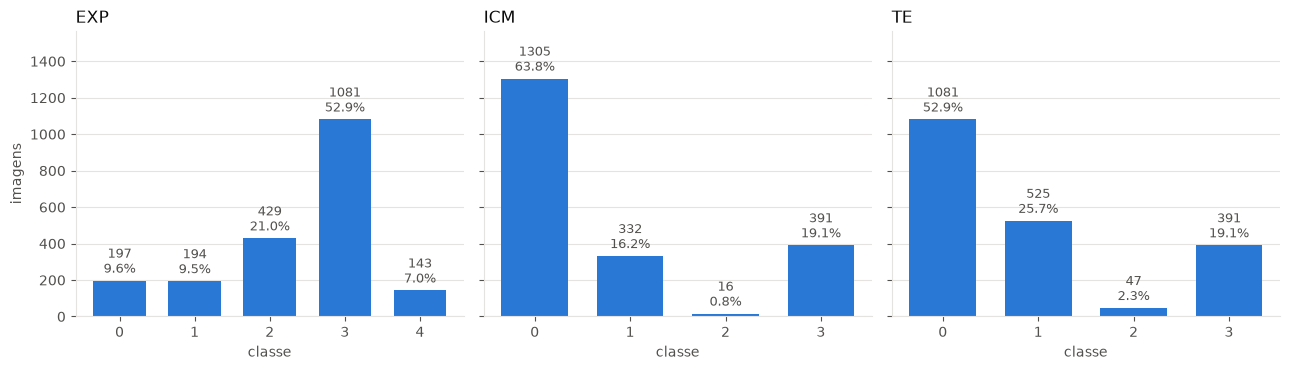

In [16]:
for target in TARGETS:
    print(target)
    display(value_table(df[target]))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, target in zip(axes, TARGETS):
    table = value_table(df[target])
    positions = [str(i) for i in table.index]
    bars = ax.bar(positions, table["imagens"], color=BLUE, width=0.7)
    ax.set_title(target, loc="left")
    ax.set_xlabel("classe")
    ax.yaxis.grid(True, color=GRID)
    ax.set_axisbelow(True)
    for bar, count, pct in zip(bars, table["imagens"], table["%"]):
        ax.text(bar.get_x() + bar.get_width() / 2, count + 20, f"{count}\n{pct}%", ha="center", va="bottom", fontsize=9, color=MUTED)
axes[0].set_ylabel("imagens")
axes[0].set_ylim(0, df[TARGETS].apply(lambda c: c.value_counts().max()).max() * 1.2)
fig.tight_layout()
plt.show()

## 3. A classe 3 de ICM e TE

Esta seção compara a classe 3 com o grau de expansão. Se ela sempre coincidir com EXP < 2, ela marca imagens em que a qualidade não pode ser avaliada, e não um quarto grau de qualidade.

ICM: classe 3 coincide exatamente com EXP < 2? True
TE: classe 3 coincide exatamente com EXP < 2? True
ICM e TE são classe 3 nas mesmas imagens? True


,imagens,avaliável
EXP,,
0,197,False
1,194,False
2,429,True
3,1081,True
4,143,True


Avaliáveis: 1653 (80.9%)
Não avaliáveis: 391 (19.1%)


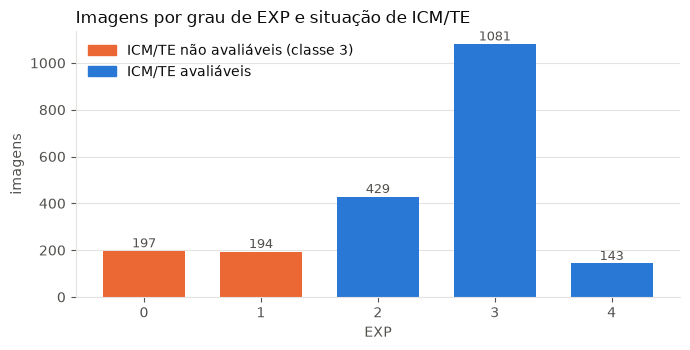

In [17]:
df["avaliavel"] = df["EXP"] >= 2

for target in ["ICM", "TE"]:
    same = ((df[target] == 3) == (df["EXP"] < 2)).all()
    print(f"{target}: classe 3 coincide exatamente com EXP < 2? {same}")
print(f"ICM e TE são classe 3 nas mesmas imagens? {((df['ICM'] == 3) == (df['TE'] == 3)).all()}")

situation = df.groupby("EXP")["avaliavel"].agg(["size", "first"]).rename(columns={"size": "imagens", "first": "avaliável"})
display(situation)
print(f"Avaliáveis: {df['avaliavel'].sum()} ({100 * df['avaliavel'].mean():.1f}%)")
print(f"Não avaliáveis: {(~df['avaliavel']).sum()} ({100 * (~df['avaliavel']).mean():.1f}%)")

fig, ax = plt.subplots(figsize=(7, 3.6))
counts = df["EXP"].value_counts().sort_index()
colors = [BLUE if e >= 2 else ORANGE for e in counts.index]
bars = ax.bar(counts.index.astype(str), counts.values, color=colors, width=0.7)
for bar, count in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, count + 15, str(count), ha="center", fontsize=9, color=MUTED)
ax.set_title("Imagens por grau de EXP e situação de ICM/TE", loc="left")
ax.set_xlabel("EXP")
ax.set_ylabel("imagens")
ax.yaxis.grid(True, color=GRID)
ax.set_axisbelow(True)
handles = [plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color=BLUE)]
ax.legend(handles, ["ICM/TE não avaliáveis (classe 3)", "ICM/TE avaliáveis"], frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

## 4. Distribuição só nas imagens avaliáveis

Sem a classe 3, ICM e TE mostram o desbalanceamento real entre os graus de qualidade.

,imagens,%
ICM (avaliáveis),,
0,1305,78.9
1,332,20.1
2,16,1.0


,imagens,%
TE (avaliáveis),,
0,1081,65.4
1,525,31.8
2,47,2.8


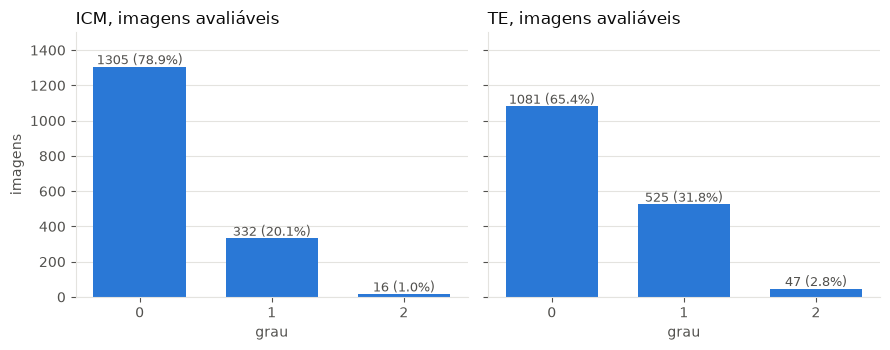

In [18]:
gradable = df[df["avaliavel"]]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, target in zip(axes, ["ICM", "TE"]):
    table = value_table(gradable[target])
    display(table.rename_axis(f"{target} (avaliáveis)"))
    bars = ax.bar(table.index.astype(str), table["imagens"], color=BLUE, width=0.7)
    ax.set_title(f"{target}, imagens avaliáveis", loc="left")
    ax.set_xlabel("grau")
    ax.yaxis.grid(True, color=GRID)
    ax.set_axisbelow(True)
    for bar, count, pct in zip(bars, table["imagens"], table["%"]):
        ax.text(bar.get_x() + bar.get_width() / 2, count + 15, f"{count} ({pct}%)", ha="center", fontsize=9, color=MUTED)
axes[0].set_ylabel("imagens")
axes[0].set_ylim(0, gradable[["ICM", "TE"]].apply(lambda c: c.value_counts().max()).max() * 1.15)
fig.tight_layout()
plt.show()

## 5. Cruzamentos entre as colunas

Cada célula mostra o número de imagens com aquela combinação de duas colunas. Os percentuais por linha mostram como a segunda coluna muda conforme a primeira.

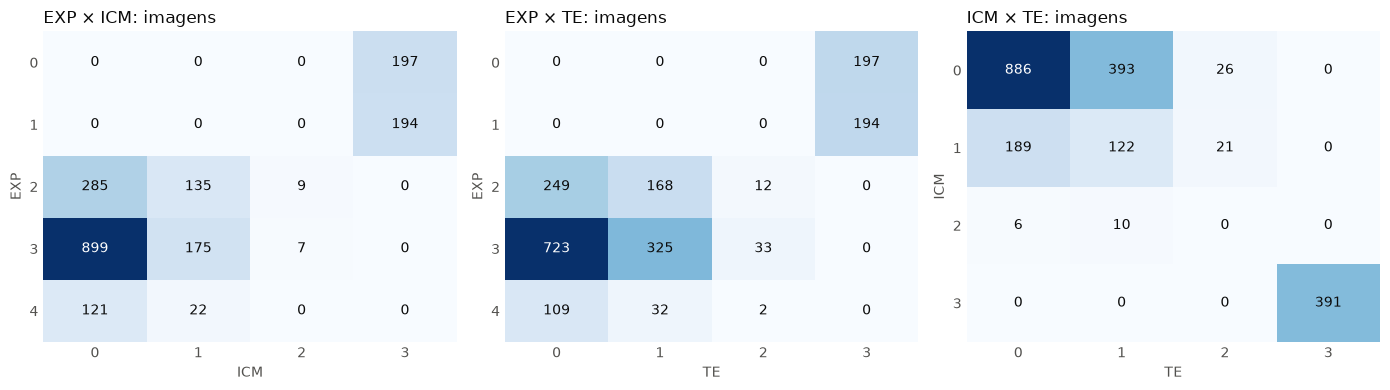

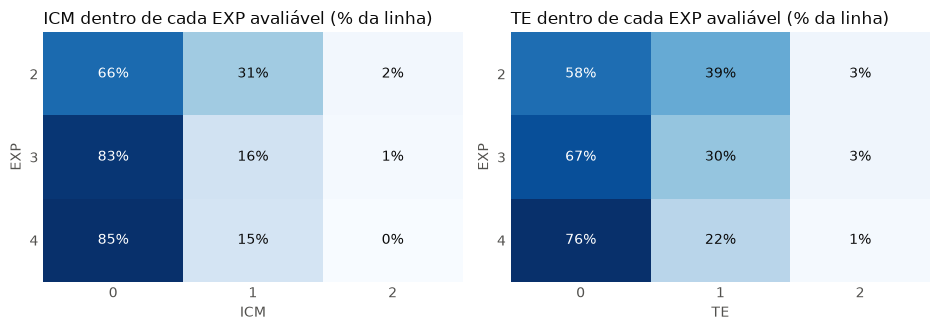

Correlação de Spearman nas imagens avaliáveis:


,EXP,ICM,TE
EXP,1.000,-0.170,-0.103
ICM,-0.170,1.000,0.111
TE,-0.103,0.111,1.000


In [19]:
pairs = [("EXP", "ICM"), ("EXP", "TE"), ("ICM", "TE")]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (a, b) in zip(axes, pairs):
    heatmap(ax, pd.crosstab(df[a], df[b]), f"{a} × {b}: imagens")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
for ax, target in zip(axes, ["ICM", "TE"]):
    share = pd.crosstab(gradable["EXP"], gradable[target], normalize="index").mul(100).round(0).astype(int)
    heatmap(ax, share, f"{target} dentro de cada EXP avaliável (% da linha)", fmt="{:d}%")
fig.tight_layout()
plt.show()

print("Correlação de Spearman nas imagens avaliáveis:")
display(gradable[TARGETS].corr(method="spearman").round(3))

## 6. Combinações completas (EXP, ICM, TE)

Esta seção conta as combinações dos três valores, que mostram os perfis realmente presentes nos dados.

Combinações existentes: 24 de 29 possíveis (3 EXP avaliáveis × 3 ICM × 3 TE, mais 2 EXP não avaliáveis)
Combinações com até 1 imagem(ns): 2
Combinações com até 5 imagem(ns): 5
Combinações com até 10 imagem(ns): 9


,combinação,imagens,%,% acumulado
0,EXP 3 · ICM 0 · TE 0,622,30.4,30.4
1,EXP 3 · ICM 0 · TE 1,258,12.6,43.1
2,EXP 0 · ICM 3 · TE 3,197,9.6,52.7
3,EXP 1 · ICM 3 · TE 3,194,9.5,62.2
4,EXP 2 · ICM 0 · TE 0,169,8.3,70.5
5,EXP 2 · ICM 0 · TE 1,110,5.4,75.8
6,EXP 3 · ICM 1 · TE 0,98,4.8,80.6
7,EXP 4 · ICM 0 · TE 0,95,4.6,85.3
8,EXP 2 · ICM 1 · TE 0,77,3.8,89.0
9,EXP 3 · ICM 1 · TE 1,63,3.1,92.1


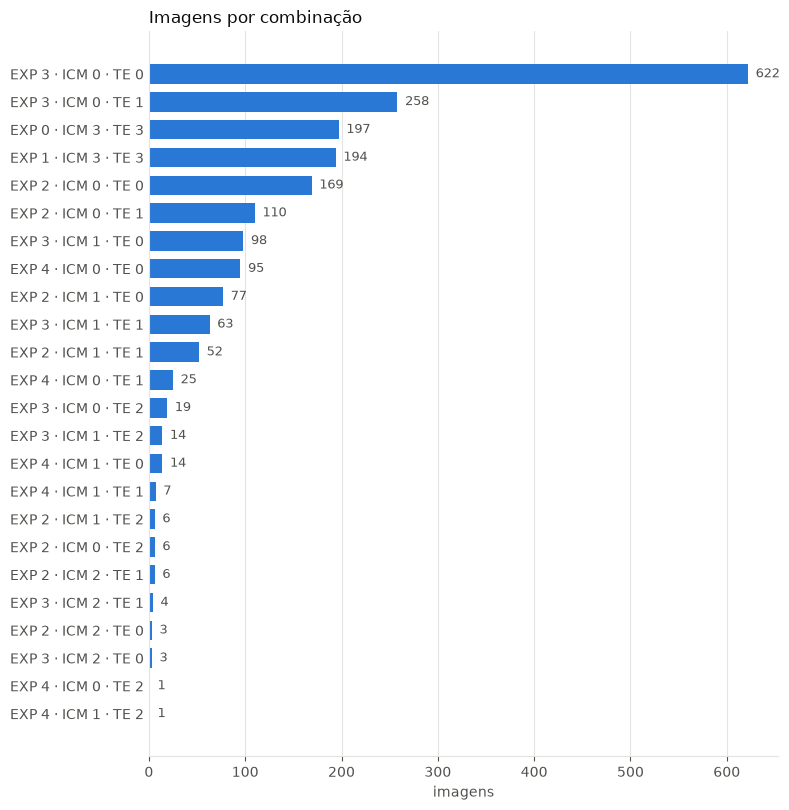

In [20]:
combos = (df.groupby(TARGETS).size().sort_values(ascending=False).rename("imagens").reset_index())
combos["%"] = (100 * combos["imagens"] / len(df)).round(1)
combos["% acumulado"] = (100 * combos["imagens"].cumsum() / len(df)).round(1)
combos["combinação"] = "EXP " + combos["EXP"].astype(str) + " · ICM " + combos["ICM"].astype(str) + " · TE " + combos["TE"].astype(str)

possible = 3 * 3 * 3 + 2
print(f"Combinações existentes: {len(combos)} de {possible} possíveis (3 EXP avaliáveis × 3 ICM × 3 TE, mais 2 EXP não avaliáveis)")
for limit in [1, 5, 10]:
    print(f"Combinações com até {limit} imagem(ns): {(combos['imagens'] <= limit).sum()}")
display(combos[["combinação", "imagens", "%", "% acumulado"]])

ranked = combos.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 0.3 * len(ranked) + 1))
ax.barh(ranked["combinação"], ranked["imagens"], color=BLUE, height=0.7)
for y, count in enumerate(ranked["imagens"]):
    ax.text(count + 8, y, str(count), va="center", fontsize=9, color=MUTED)
ax.set_title("Imagens por combinação", loc="left")
ax.set_xlabel("imagens")
ax.xaxis.grid(True, color=GRID)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
plt.show()

## 7. Imagens por embrião

O nome do arquivo revela o embrião. Um mesmo embrião pode ter várias imagens, o que importa para separar treino e validação sem vazamento.

,imagens
count,802.00
mean,2.55
std,1.71
min,1.00
25%,1.00
50%,2.00
75%,3.00
max,11.00


Embriões com 1 imagem: 276 (34.4%)


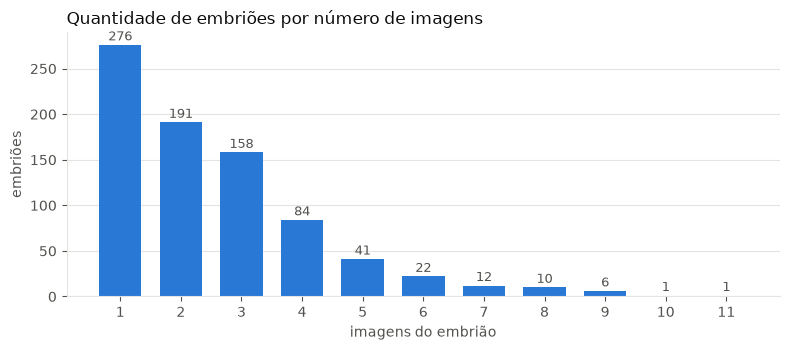

Os rótulos mudam entre imagens do mesmo embrião?


,coluna,embriões com mais de 1 imagem,com rótulos diferentes,%
0,EXP,526,407,77.4
1,ICM,526,335,63.7
2,TE,526,383,72.8


Embriões em que EXP nunca diminui conforme o número da imagem aumenta: 198 de 526 (37.6%)


,imagens,EXP médio
image_number,,
1,735,2.52
2,506,2.25
3,327,2.20
4,219,2.31
5,107,2.48
6,65,2.48


Formato do identificador do embrião:


,imagens,embriões
embryo_id,,
3 dígitos,1564,614
4 dígitos,480,188


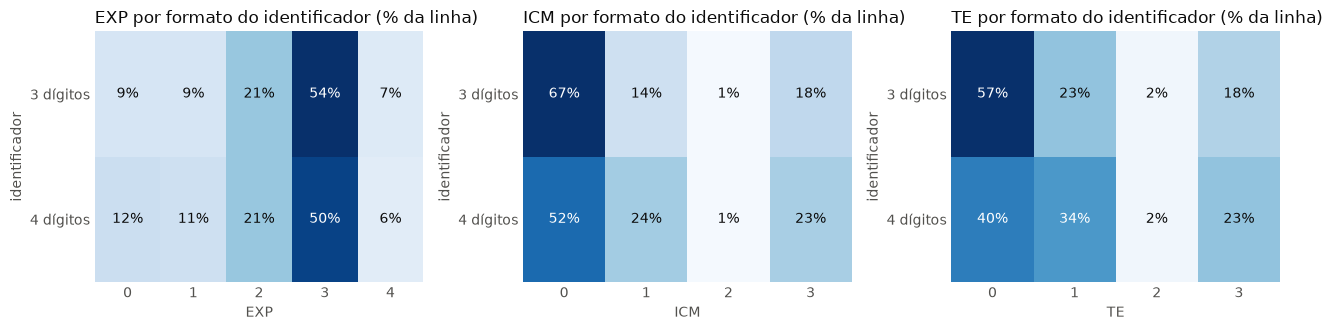

In [9]:
per_embryo = df.groupby("embryo_id").size().rename("imagens")
display(per_embryo.describe().round(2).to_frame())
distribution = per_embryo.value_counts().sort_index()
print(f"Embriões com 1 imagem: {distribution.get(1, 0)} ({100 * distribution.get(1, 0) / len(per_embryo):.1f}%)")

fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(distribution.index.astype(str), distribution.values, color=BLUE, width=0.7)
for bar, count in zip(bars, distribution.values):
    ax.text(bar.get_x() + bar.get_width() / 2, count + 5, str(count), ha="center", fontsize=9, color=MUTED)
ax.set_title("Quantidade de embriões por número de imagens", loc="left")
ax.set_xlabel("imagens do embrião")
ax.set_ylabel("embriões")
ax.yaxis.grid(True, color=GRID)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

multi = df[df["embryo_id"].isin(per_embryo[per_embryo > 1].index)]
rows = []
for target in TARGETS:
    distinct = multi.groupby("embryo_id")[target].nunique()
    rows.append({"coluna": target, "embriões com mais de 1 imagem": len(distinct), "com rótulos diferentes": int((distinct > 1).sum()), "%": round(100 * (distinct > 1).mean(), 1)})
print("Os rótulos mudam entre imagens do mesmo embrião?")
display(pd.DataFrame(rows))

ordered = multi.sort_values(["embryo_id", "image_number"])
same_or_up = ordered.groupby("embryo_id")["EXP"].apply(lambda s: (s.diff().dropna() >= 0).all())
print(f"Embriões em que EXP nunca diminui conforme o número da imagem aumenta: {same_or_up.sum()} de {len(same_or_up)} ({100 * same_or_up.mean():.1f}%)")
by_number = df[df["image_number"] <= 6].groupby("image_number")["EXP"].agg(["size", "mean"]).round(2).rename(columns={"size": "imagens", "mean": "EXP médio"})
display(by_number)

id_length = df["embryo_id"].str.len().map({3: "3 dígitos", 4: "4 dígitos"})
print("Formato do identificador do embrião:")
display(pd.DataFrame({"imagens": id_length.value_counts(), "embriões": df.groupby(id_length)["embryo_id"].nunique()}))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, target in zip(axes, TARGETS):
    share = pd.crosstab(id_length, df[target], normalize="index").mul(100).round(0).astype(int).rename_axis("identificador")
    heatmap(ax, share, f"{target} por formato do identificador (% da linha)", fmt="{:d}%")
fig.tight_layout()
plt.show()

## 8. Classes raras na separação treino/validação

Esta tabela usa a mesma separação por embrião do notebook de treino (`GroupShuffleSplit`, 15%, seed 42). Ela mostra quantos exemplos de cada classe sobram em cada conjunto.

In [10]:
train_idx, val_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED).split(df, groups=df["embryo_id"]))
rows = []
for target in TARGETS:
    train_counts = df.iloc[train_idx][target].value_counts()
    val_counts = df.iloc[val_idx][target].value_counts()
    for value in sorted(df[target].unique()):
        rows.append({"alvo": target, "classe": value, "treino": train_counts.get(value, 0), "validação": val_counts.get(value, 0)})
print(f"Treino: {len(train_idx)} imagens | Validação: {len(val_idx)} imagens")
display(pd.DataFrame(rows).set_index(["alvo", "classe"]))

Treino: 1743 imagens | Validação: 301 imagens


treino  validação
alvo classe                   
EXP  0          168         29
     1          173         21
     2          373         56
     3          913        168
     4          116         27
ICM  0         1103        202
     1          287         45
     2           12          4
     3          341         50
TE   0          914        167
     1          448         77
     2           40          7
     3          341         50

## 9. Exemplos de imagens de cada classe

Cada linha mostra até 4 imagens de uma classe, sorteadas de embriões diferentes. A semente é fixa, então os exemplos se repetem a cada execução.

Tamanho (largura, altura): {(512, 384): 2044}
Modo de cor: {'RGB': 2044}


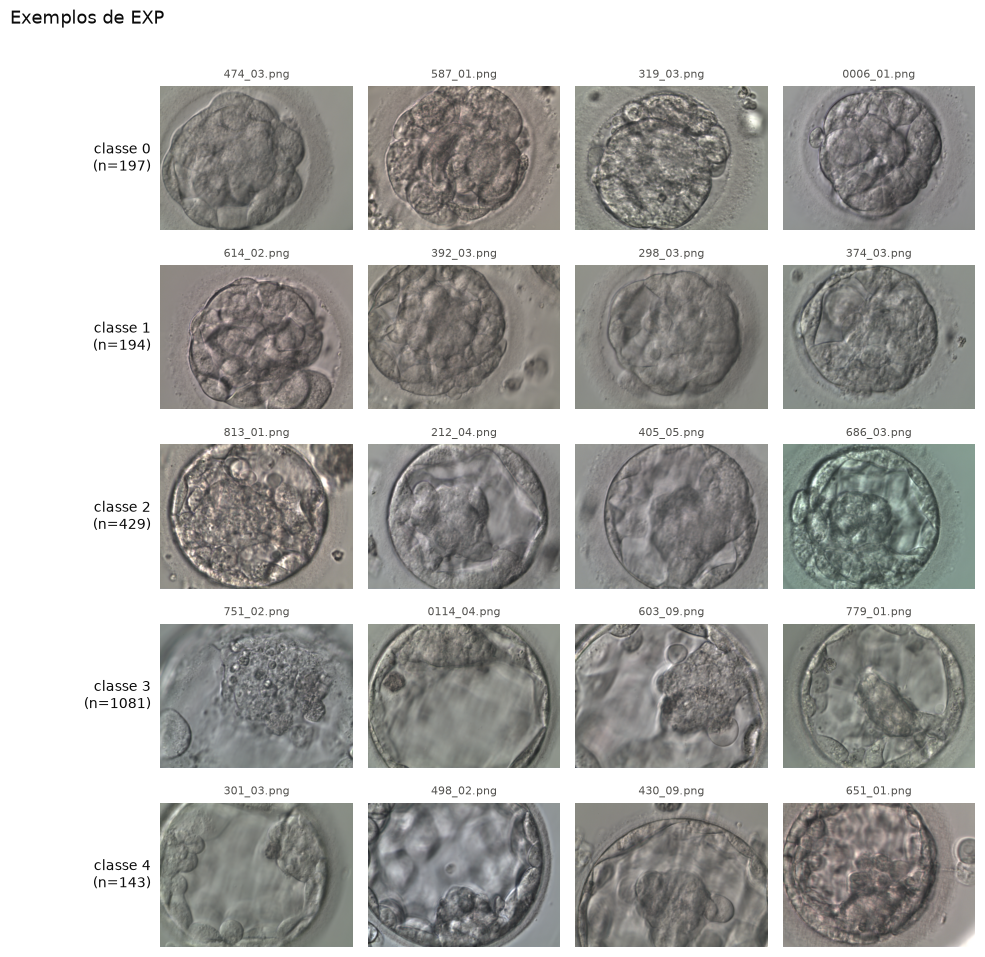

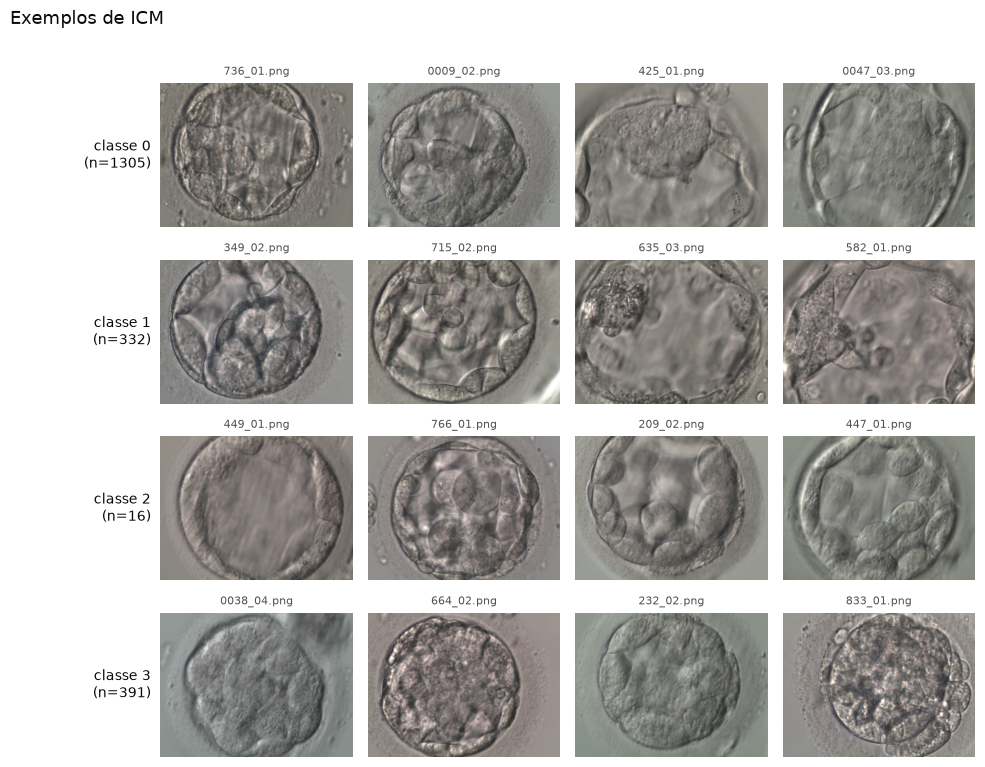

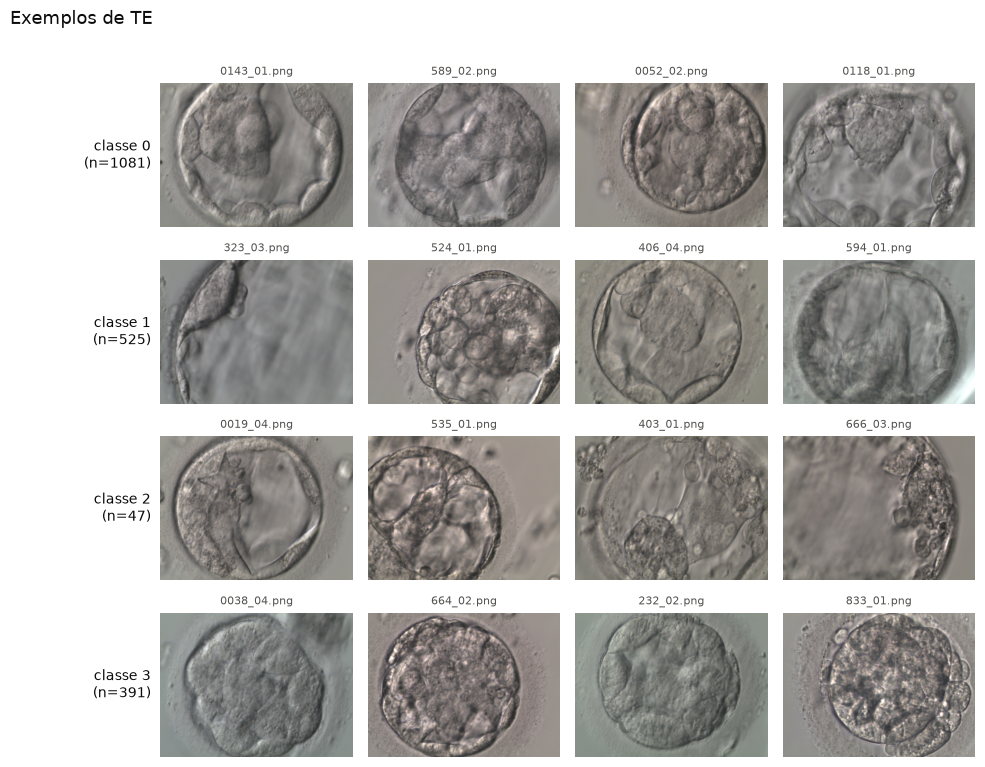

In [11]:
sizes = pd.Series([Image.open(os.path.join(IMAGES_DIR, n)).size for n in df["Image"]]).value_counts()
modes = pd.Series([Image.open(os.path.join(IMAGES_DIR, n)).mode for n in df["Image"]]).value_counts()
print("Tamanho (largura, altura):", sizes.to_dict())
print("Modo de cor:", modes.to_dict())

N_EXAMPLES = 4
for target in TARGETS:
    classes = sorted(df[target].unique())
    fig, axes = plt.subplots(len(classes), N_EXAMPLES, figsize=(10, 1.95 * len(classes)))
    fig.suptitle(f"Exemplos de {target}", x=0.02, ha="left", fontsize=13)
    for row, value in zip(axes, classes):
        subset = df[df[target] == value].drop_duplicates("embryo_id")
        sample = subset.sample(min(N_EXAMPLES, len(subset)), random_state=SEED)
        for ax in row:
            ax.axis("off")
        for ax, name in zip(row, sample["Image"]):
            ax.imshow(Image.open(os.path.join(IMAGES_DIR, name)))
            ax.set_title(name, fontsize=8, color=MUTED)
        row[0].text(-0.05, 0.5, f"classe {value}\n(n={int((df[target] == value).sum())})", transform=row[0].transAxes, ha="right", va="center", fontsize=10)
    fig.tight_layout(rect=(0.08, 0, 1, 0.97))
    plt.show()

## 10. Resumo

- **Tamanho:** 2.044 linhas, 802 embriões, sem valores ausentes. Todas as imagens têm 512×384 pixels, em RGB.
- **Inconsistências:** a imagem `838_02.png` aparece duas vezes, com EXP 3 e EXP 4. O arquivo `846_01.png` existe na pasta, mas não está em nenhum CSV.
- **EXP:** a classe 3 concentra 52,9% das imagens, e a classe 4 é a menor, com 7,0%.
- **Classe 3 de ICM e TE:** são 391 imagens (19,1%), exatamente as que têm EXP 0 ou 1. Isso indica que ela marca imagens não avaliáveis, e não um grau de qualidade. A interpretação vem dos dados, não de uma documentação.
- **Imagens avaliáveis:** nas 1.653 restantes, o desbalanceamento é forte: ICM tem 78,9% no grau 0 e só 16 imagens (1,0%) no grau 2; TE tem 65,4% no grau 0 e 47 imagens (2,8%) no grau 2.
- **Relação entre os alvos:** nas imagens avaliáveis, as correlações de Spearman são fracas (de -0,170 a 0,111), então um alvo diz pouco sobre o outro.
- **Combinações:** existem 24 das 29 possíveis. A mais comum, EXP 3 · ICM 0 · TE 0, tem 30,4% das imagens, e 9 combinações têm até 10 imagens.
- **Embriões:** a média é de 2,55 imagens por embrião (de 1 a 11), e 34,4% têm só uma.
- **Rótulos dentro do embrião:** entre os 526 embriões com mais de uma imagem, EXP muda em 77,4%, ICM em 63,7% e TE em 72,8%. Portanto, os rótulos pertencem à imagem, não ao embrião. O número da imagem não indica um avanço claro: EXP nunca diminui em só 37,6% desses embriões.
- **Separação treino/validação:** a validação fica com apenas 4 imagens de ICM=2 e 7 de TE=2, o que torna as métricas dessas classes muito instáveis.
- **Origem dos identificadores:** embriões com identificador de 4 dígitos têm distribuição de ICM e TE diferente da dos de 3 dígitos, por exemplo 52% contra 67% em ICM=0. Isso pode indicar origens diferentes, mas os dados não confirmam.
